In [1]:
#IMPORT LIBS
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from datetime import timedelta
import cartopy.util as cutil
import pandas as pd
#import statsmodels.api as sm
from tqdm import tqdm

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
#CMIP6 trajectories

### Definitions

In [3]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(60, 82.5, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-70, -17.5, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

In [4]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [5]:
def rollmean_spline_DA(DA,roll_avg_periods=3*10,s_spline=0):
    import scipy.interpolate as spi
    
    #Rolling mean
    rolling_mean = DA.rolling(time=roll_avg_periods, center=True).mean()
    freq = rolling_mean.values
    valid_idx = ~np.isnan(freq)
    
    #create x_ticks
    every_n_months = 30
    x_ticks = []
    locations = np.arange(0,len(freq[valid_idx]),every_n_months)
    for t,time in enumerate(DA['time'][valid_idx]):
        if t%every_n_months == 0:
            x_ticks.append(str(time.values)[:4])
    #spline
    spline = spi.UnivariateSpline(np.arange(len(freq[valid_idx])),freq[valid_idx], k=3, s=s_spline)
    xs = DA['time'].values[valid_idx]
    ys = spline(np.arange(len(freq[valid_idx])))

    return ys,xs,locations,x_ticks

### Importing Data

In [6]:
'''
Importing the dictionaries
'''
import os
# Path to the dataset directory
dictionaries_path = "/disco/share/jm1427/greenblock/TRACKS/ssp370/GHA/"

# List all files, excluding those with 'unfilt' in the name
dic_file_list = [
    f for f in os.listdir(dictionaries_path) 
    if os.path.isfile(os.path.join(dictionaries_path, f)) and 'unfilt' not in f
]

dic_file_list = sorted(dic_file_list)
run_names_dic = get_run_names(dic_file_list)

In [7]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/disco/share/jm1427/greenblock/BI/ssp370/"

# List all files, excluding those with 'unfilt' in the name
dataset_file_list = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'unfilt' not in f and 'GHA' in f
]

dataset_file_list = sorted(dataset_file_list)
run_names_dataset = get_run_names(dataset_file_list)

In [8]:
'''
Importing the t2m datasets
'''
import os
# Path to the dataset directory
dataset_tas_path = "/disco/share/jm1427/greenblock/tas/ssp370/"

# List all files, excluding those with 'unfilt' in the name
dataset_tas_file_list = [
    f for f in os.listdir(dataset_tas_path) 
    if os.path.isfile(os.path.join(dataset_tas_path, f))]

dataset_tas_file_list = sorted(dataset_tas_file_list)
run_names_dataset_tas = get_run_names(dataset_tas_file_list)

In [9]:
'''
Importing the height datasets
'''
import os
# Path to the dataset directory
dataset_height_path = "/disco/share/jm1427/greenblock/zg/ssp370/"

# List all files, excluding those with 'unfilt' in the name
dataset_height_file_list = [
    f for f in os.listdir(dataset_height_path) 
    if os.path.isfile(os.path.join(dataset_height_path, f))]

dataset_height_file_list = sorted(dataset_height_file_list)
run_names_dataset_height = get_run_names(dataset_height_file_list)

In [10]:
#take the intersection of the previous (only the experiments for which you have all the data)
intersection = [item for item in run_names_dataset if item in run_names_dic]# and item in run_names_dataset_tas and item in run_names_dataset_height]
print(str(len(intersection))+' experiments selected')
print(str(len(run_names_dic)-len(intersection))+' experiments excluded')

51 experiments selected
0 experiments excluded


In [11]:
#import data:
datasets = []
dics = []
#datasets_tas = []
#datasets_height = []
for item in tqdm(intersection):
    selected = [s for s in dataset_file_list if item in s][0]
    datasets.append(xr.open_dataset(dataset_path + selected))
    selected = [s for s in dic_file_list if item in s][0]
    dics.append(np.load(dictionaries_path + selected,allow_pickle=True))
    #selected = [s for s in dataset_tas_file_list if item in s][0]
    #datasets_tas.append(xr.open_dataset(dataset_tas_path + selected))
    #selected = [s for s in dataset_height_file_list if item in s][0]
    #datasets_height.append(xr.open_dataset(dataset_height_path + selected))
    

100%|███████████████████████████████████████████████████████████████████████| 51/51 [00:10<00:00,  4.72it/s]


### Selecting the events crossing Greenland in summer

In [12]:
#select the events crossing Greenland in summer.

In [13]:
labels = []
timings = []
new_dics = []
months = ['06','07','08']
min_pers = 3
mask_size = np.sum(mask_xr,axis=(0,1))
start=0
end=51
for i,dic in tqdm(enumerate(dics[start:end])):
    labels.append([])
    timings.append([])
    new_dics.append([])
    times = datasets[i+start]['time']
    GHA_filt = datasets[i+start]['GHA_tracked']
    for t,time in enumerate(times):
        month = str(time.values)[5:7]
        if t > len(times.values)-min_pers:
            break
        if month in months:
            labels_of_the_day = np.unique(GHA_filt.values[t,mask_bool])
            for label in labels_of_the_day[1:]:
                check_cond = []
                for k in range(min_pers):
                    check_cond.append(np.any(GHA_filt.values[t+k,mask_bool]==label))
                if label not in labels[i] and np.all(check_cond) and label!=0:
                    labels[i].append(label)
                    timings[i].append(t)
                    new_dics[i].append(dics[i][label])
                    new_dics[i][-1]['time_arrival_GR'] = t
                    new_dics[i][-1]['day_arrival_GR'] = time
                    new_dics[i][-1]['original_label'] = label
                    dics[i][label]['day_of_arrival'] = time


51it [01:57,  2.30s/it]


In [14]:
#export characteristics dictionaries
for i,element in enumerate(new_dics):
    np.save('/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/CMIP6_future/'+intersection[i]+'_dic_GR_block_GHA_jja.npy',np.array(element))

In [15]:
#store trajectory and WBI
trajectories = []
WBIs = []
retrograding_labs = []
upstream_labs = []
retrograding_labs = []
upstream_labs = []
retrograding_tracks = []
upstream_tracks = []
tot_len = 0

for i,dic in tqdm(enumerate(dics[start:end])):
    trajectories.append([])
    WBIs.append([])
    for l in labels[i]:
        trajectories[i].append(dics[i][l]['track'])
        WBIs[i].append(np.mean(dics[i][l]['WBI'])) 
        if np.mean(dics[i][l]['WBI']) > 0:
            retrograding_labs.append([])
            retrograding_tracks.append([])
            retrograding_labs[i].append(l)
            retrograding_tracks[i].append(dics[i][l]['track'])
        if np.mean(dics[i][l]['WBI']) <= 0:
            upstream_labs.append([])
            upstream_tracks.append([])
            upstream_labs[i].append(l)
            upstream_tracks[i].append(dics[i][l]['track'])
    tot_len += len(WBIs[i])

51it [00:00, 160.35it/s]


### Computing and plotting trajectories

In [16]:
tot_xs = []
tot_ys = []
for i,dic in tqdm(enumerate(dics[start:end])):
    for track in trajectories[i]:
        for x in track[1]:
            tot_xs.append(x)
        for y in track[0]:
            tot_ys.append(y)
retrograding_xs = []
retrograding_ys = []
retrograding_len = 0
for i,dic in tqdm(enumerate(dics[start:end])):
    for track in retrograding_tracks[i]:
        retrograding_len += 1
        for x in track[1]:
            retrograding_xs.append(x)
        for y in track[0]:
            retrograding_ys.append(y)
upstream_xs = []
upstream_ys = []
upstream_len = 0
for i,dic in tqdm(enumerate(dics[start:end])):
    for track in upstream_tracks[i]:
        upstream_len += 1
        for x in track[1]:
            upstream_xs.append(x)
        for y in track[0]:
            upstream_ys.append(y)

51it [00:00, 1545.66it/s]
51it [00:00, 3142.40it/s]
51it [00:00, 3041.73it/s]


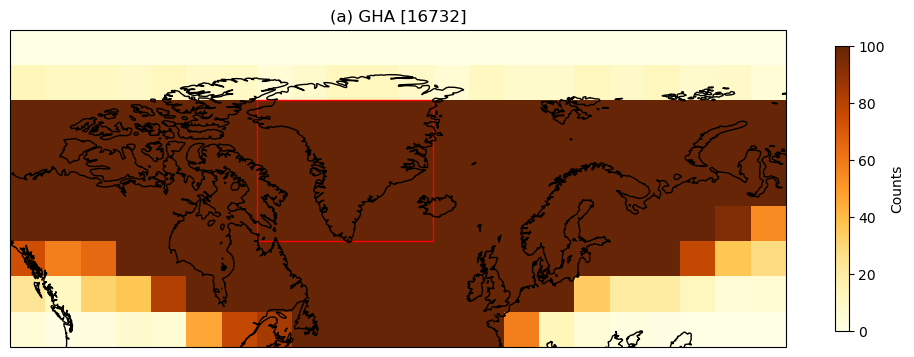

In [17]:
'''
TRAJECTORY PLOT
'''
from matplotlib.patches import Rectangle

# Define the global latitude and longitude ranges
lat = np.arange(0, 91, 2.5)  # From 0°N to 90°N
lon = np.arange(-180, 180, 2.5)  # From -180°E to 180°E

fig, axarr = plt.subplots(nrows=1, ncols=1, figsize=(10, 6), subplot_kw={'projection': ccrs.PlateCarree()})
title = '(a) GHA [' + str(tot_len) + ']'
datacrs = ccrs.PlateCarree()
extent =[-140,+80,45,90]

j = 0
axarr.coastlines()
axarr.set_aspect(2.0)
axarr.set_title(title)

hist = axarr.hist2d(tot_xs, tot_ys, bins=(36, 18), range=[[-180, 180], [0, 90]], cmap='YlOrBr',vmin=0,vmax=100,transform=datacrs)  # Adjust bins as needed

box = Rectangle(
    (lon_min, lat_min),  # Bottom-left corner
    lon_max - lon_min,   # Width (longitude difference)
    lat_max - lat_min,   # Height (latitude difference)
    linewidth=1,
    edgecolor='red',
    facecolor='none',  # Transparent fill
    transform=datacrs  # Ensure proper projection
)

cb = plt.colorbar(hist[3], ax=axarr, orientation='vertical', pad=0.05, shrink = 0.5, label='Counts')

# Add the box to the plot
axarr.add_patch(box)
    
axarr.set_extent(extent,crs=datacrs)

plt.tight_layout()
plt.show()    

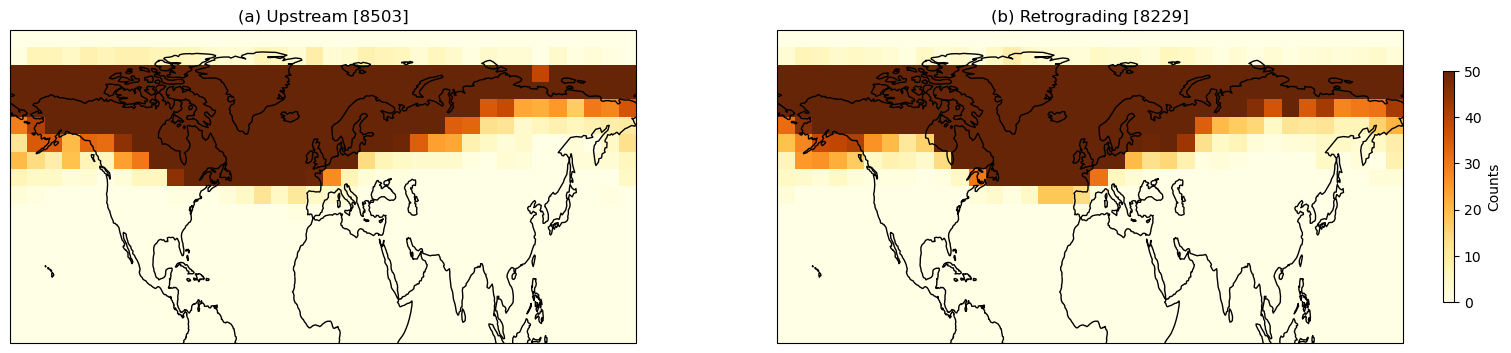

In [18]:
'''
TRAJECTORY PLOT
'''
from matplotlib.patches import Rectangle


fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(20, 6), subplot_kw={'projection': ccrs.PlateCarree()},gridspec_kw={'width_ratios': [1, 1.25]})
titles = ['(a) Upstream [' + str(upstream_len) + ']','(b) Retrograding [' + str(retrograding_len) + ']']
datacrs = ccrs.PlateCarree()
extent =[-140,+80,45,90]
#extent =[-180,+180,45,90]

for j in range(2):
    axarr[j].coastlines()
    axarr[j].set_aspect(2.0)
    axarr[j].set_title(titles[j])

    box = Rectangle(
        (lon_min, lat_min),  # Bottom-left corner
        lon_max - lon_min,   # Width (longitude difference)
        lat_max - lat_min,   # Height (latitude difference)
        linewidth=1,
        edgecolor='red',
        facecolor='none',  # Transparent fill
        transform=datacrs  # Ensure proper projection
    )
    
    # Add the box to the plot
    axarr[j].add_patch(box)
        
    axarr[j].set_extent(extent,crs=datacrs)

hist1 = axarr[0].hist2d(upstream_xs, upstream_ys, bins=(36, 18), range=[[-180, 180], [0, 90]], cmap='YlOrBr',vmin=0,vmax=50,transform=datacrs)  # Adjust bins as needed
hist2 = axarr[1].hist2d(retrograding_xs, retrograding_ys, bins=(36, 18), range=[[-180, 180], [0, 90]], cmap='YlOrBr',vmin=0,vmax=50,transform=datacrs)  # Adjust bins as needed
#cb = plt.colorbar(hist1[3], ax=axarr[0], orientation='horizontal', pad=0.05, shrink = 0.5, label='Counts')
cb2 = plt.colorbar(hist2[3], ax=axarr[1], orientation='vertical', pad=0.05, shrink = 0.5, label='Counts')

#plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure1.png')
    

### Computing and plotting composites

In [19]:
#T2M composite
zgs = []
tass = []
counter = 0

for i,exp_labels in tqdm(enumerate(labels)):
    for lab in exp_labels:
        date = dics[i][lab]['date']
        persistence = dics[i][lab]['persistence']
        for t in range(persistence):
            counter += 1
            step = date + np.timedelta64(t, 'D')
            if str(step)[5:7] in months:
                zgs.append(datasets_height[i]['zg'].loc[step])
                tass.append(datasets_tas[i]['tas'].loc[step])
    print(datasets_tas[i]['tas'].shape,intersection[i])

0it [00:00, ?it/s]


NameError: name 'datasets_height' is not defined

In [ ]:
#print(tass[0].shape)
#for i,tas in enumerate(tass):
#    if tas.shape != (57,22):
#        print(tas.shape)
#tas_composite = np.mean(np.array(tass))
zgs_composite = sum(zgs)/counter

In [ ]:
print(zgs[0].shape)
for i,zg in enumerate(zgs):
    if zg.shape != (29,57):
        print(zg.shape)

In [ ]:
plt.contourf(zgs_composite)

### Computing and plotting frequency trend

In [20]:
#Method 1

freqs = []
for j,dataset in tqdm(enumerate(datasets[start:end])):
    
    times = dataset['time']
    GHA_filt = dataset['GHA_tracked']
    count_GHA = np.zeros((3))
    count_m = 0 
    freq_per_month_GHA = [[],[],[]]
    mask_size = np.sum(mask_xr,axis=(0,1))
    tmp = '06'
    check=0
    for t,time in enumerate(times):
        GHA_gr = GHA_filt.values[t,mask_bool]
        month = str(time.values)[5:7]
        if month in months:
            #method3
            count_m += 1
            for l in np.unique(GHA_gr):
                blocked_grid_points = np.sum(GHA_gr==l)
                if l in labels[j]:
                    count_GHA[0] += blocked_grid_points
                if l in retrograding_labs[j]:
                    count_GHA[1] += blocked_grid_points
                if l in upstream_labs[j]:
                    count_GHA[2] += blocked_grid_points
                    
            if month != tmp:
                check += 1
                tmp = month
                freq_per_month_GHA[0].append(count_GHA[0]/(count_m*mask_size))
                freq_per_month_GHA[1].append(count_GHA[1]/(count_m*mask_size))
                freq_per_month_GHA[2].append(count_GHA[2]/(count_m*mask_size))
                count_GHA = np.zeros((3))
                count_m = 0
        
    freq_per_month_GHA_DA = []
    
    for i,f in enumerate(freq_per_month_GHA):
        # Define a time range
        date_range = pd.date_range(str(times[0].values),end=str(times[-1].values), freq="ME")
        # Define the months to keep
        selected_months = [6,7,8]
        # Filter the date range based on the months
        filtered_dates = date_range[date_range.month.isin(selected_months)]
        #filtered_dates = filtered_dates[:-1] # correction to avoid error
        # Create the DataArray
        freq_per_month_GHA_DA.append(xr.DataArray(
        data=freq_per_month_GHA[i],  # Optional: Leave as None or provide some data
        dims=["time"],  # Define the dimension
        coords={"time": filtered_dates[:len(freq_per_month_GHA[i])]},  # Define the coordinate
        name="GHA monthly blocking frequency",  # Optional: Name of the DataArray
        attrs={"description": "GHA monthly blocking frequency over greenland"}  # Optional: Attributes
        ))
    '''
    # NORMALIZATION
    date0 = '1940-06-30 06:00:00'
    date1 = '1990-06-30 06:00:00'
    
    freq_per_month_GHA_DA_normalized = []
    for freq in freq_per_month_GHA_DA:
        freq_per_month_GHA_DA_normalized.append((freq-freq.loc[date0:date1].mean())/freq.loc[date0:date1].mean())
    '''
    freqs.append(freq_per_month_GHA_DA)

51it [02:06,  2.49s/it]


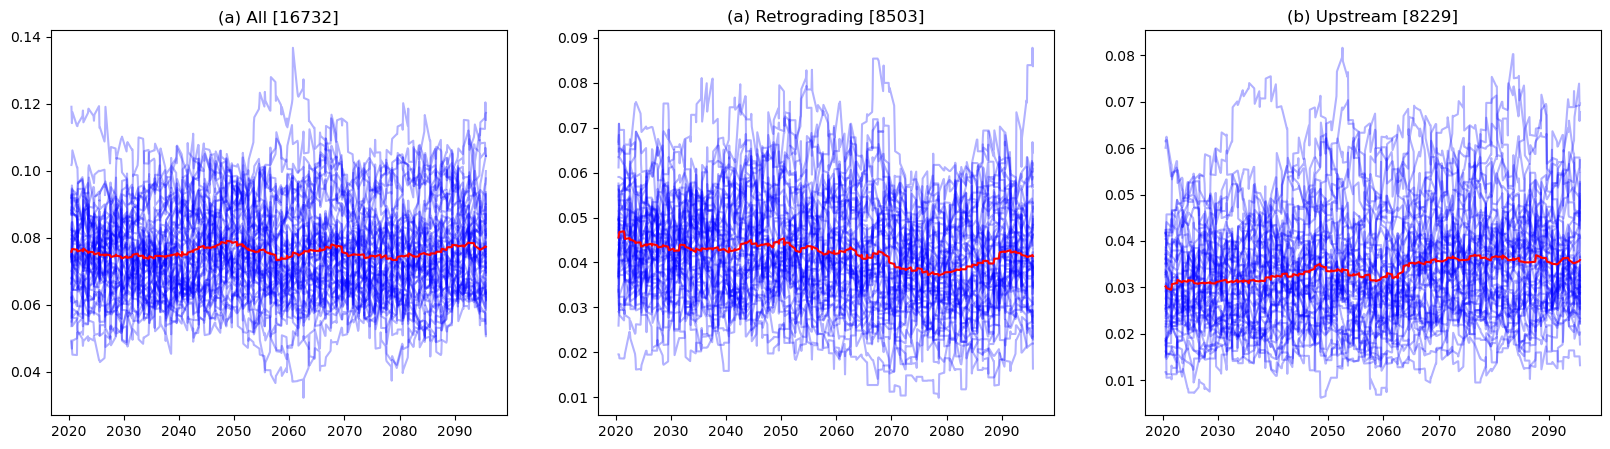

In [21]:
fig, axarr = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
titles = ['(a) All ['+ str(upstream_len+retrograding_len) + ']','(a) Retrograding [' + str(upstream_len) + ']','(b) Upstream [' + str(retrograding_len) + ']']

end = 51

for j in range(3): 
    mean = []
    for i in range(end-start): #number of experiments
        mean.append(freqs[i][j])
        ys,xs,locations,x_ticks = rollmean_spline_DA(freqs[i][j],roll_avg_periods=3*10,s_spline=0)
        axarr[j].plot(xs,ys,color='blue',alpha=0.3)

    mean = xr.concat(mean,dim='ens').mean('ens')
    ys,xs,locations,x_ticks = rollmean_spline_DA(mean,roll_avg_periods=3*10,s_spline=0)
    axarr[j].plot(xs,ys,color='red',alpha=1)
    #axarr[j].set_ylim((-1.5,1.5))
    
    axarr[j].set_title(titles[j])

In [22]:
#export frequency data_arrays
block_type = ['all','retrograding','upstream']
for i,freq in enumerate(freqs):
    for j,DA in enumerate(freq):
        DA.to_netcdf('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays/ssp370/' + intersection[i] + '_freq_' + block_type[j] + '_GHA_ssp370.nc')